# Bias Demonstration

**How wrong would the estimate be without random assignment?** Companies usually email the customers who look most likely to buy. Comparing emailed with non-emailed customers then mixes the email's effect with the difference between the two groups of customers. This notebook builds such targeted data from the experiment and compares three estimates with the experiment's own result. It answers no challenge question.

**Method:** RCT rejection sampling ([Keith et al., 2023](https://arxiv.org/abs/2307.15176)) drops customers at random, depending on their features and group, so that the email goes mostly to some customers while the experiment's result remains the benchmark. The score, the scenarios and the 10% threshold are this project's own choices.

The design was fixed in [`DECISIONS.md`](../DECISIONS.md) (2026-11-25) before this notebook was run:

- **Data:** the Mens E-Mail and No E-Mail groups, 42,613 customers. The benchmark is the experiment's estimate on these customers.
- **Who looks likely to buy:** one point each for a purchase in the last 3 months and for \$200 or more of past-year spend, a score from 0 to 2.
- **Targeting:** in three scenarios, the share of customers emailed for scores 0, 1 and 2 is 50/50/50 (random, a check), 30/50/70 and 10/50/90.
- **Three estimates:** the plain difference; adjusted for both features; adjusted for past-year spend only, as if recency had not been recorded.
- **Criterion:** 1,000 samples per scenario, seed 42. **Bias counts as removed if its absolute value is below 10% of the benchmark.**

**This is a demonstration, not a finding.** Stage 02 had already shown that recent customers spend more even without an email, so the plain difference was expected to overstate the effect.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("..")
from src.prepare import SEED, load_data

REPS = 1_000
SCENARIOS = {  # share of customers emailed for scores 0, 1 and 2
    "Random (check)": (0.5, 0.5, 0.5),
    "Moderate targeting": (0.3, 0.5, 0.7),
    "Strong targeting": (0.1, 0.5, 0.9),
}
MAX_SHARE = 0.9  # the largest share in any scenario, so every keep probability is at most 1

df = load_data()
df = df[df["segment"] != "Womens E-Mail"].reset_index(drop=True)
emailed = (df["segment"] == "Mens E-Mail").to_numpy()
recent = (df["recency"] <= 3).to_numpy()
high = (df["history"] >= 200).to_numpy()
score = recent.astype(int) + high.astype(int)
spend = df["spend"].to_numpy()

counts = pd.crosstab(pd.Series(score, name="score"), pd.Series(np.where(emailed, "Mens E-Mail", "No E-Mail"), name="group"))
counts["all"] = counts.sum(axis=1)
counts

group,Mens E-Mail,No E-Mail,all
score,,,
0,8894,8903,17797
1,8465,8510,16975
2,3948,3893,7841


**Reading the result:** **18% of these customers have a score of 2 and 42% a score of 0,** split about evenly between the two groups, as random assignment implies. These counts use features only.

## Step 1: The experimental benchmark

The difference in mean spend between the Mens E-Mail and No E-Mail groups on all 42,613 customers, as in stage 01.

In [2]:
benchmark = spend[emailed].mean() - spend[~emailed].mean()
print(f"Benchmark: the experiment's estimate on these {len(df):,} customers, ${benchmark:.4f} per customer")
print(f"Bias counts as removed below ${0.1 * benchmark:.4f} (10% of the benchmark)")

Benchmark: the experiment's estimate on these 42,613 customers, $0.7698 per customer
Bias counts as removed below $0.0770 (10% of the benchmark)


## Step 2: Build targeted samples from the experiment

In each scenario, a customer with score s is kept with probability e ÷ 0.9 if emailed and (1 − e) ÷ 0.9 if not, where e is the scenario's share for that score. Among kept customers with score s, the share emailed is then e.

In [3]:
def keep_probability(shares):
    """RCT rejection sampling: keep emailed customers with e / 0.9 and the others with (1 - e) / 0.9."""
    e = np.asarray(shares)[score]
    return np.where(emailed, e, 1 - e) / MAX_SHARE


# One sample per scenario, to check the construction. Only assignment and features are used here.
rng = np.random.default_rng(SEED)
checks = {}
for name, shares in SCENARIOS.items():
    kept = rng.random(len(df)) < keep_probability(shares)
    for s in range(3):
        group = score == s
        checks[(name, s)] = {
            "share emailed": emailed[kept & group].mean(),
            "target share": shares[s],
            "share of this score kept": kept[group].mean(),
        }
    checks[(name, "all")] = {"share emailed": emailed[kept].mean(), "target share": np.nan,
                             "share of this score kept": kept.mean()}
pd.DataFrame(checks).T.round(3)

share emailed  target share  share of this score kept
Random (check)     0            0.501           0.5                     0.554
                   1            0.509           0.5                     0.553
                   2            0.499           0.5                     0.551
                   all          0.504           NaN                     0.553
Moderate targeting 0            0.296           0.3                     0.553
                   1            0.502           0.5                     0.553
                   2            0.699           0.7                     0.560
                   all          0.453           NaN                     0.554
Strong targeting   0            0.104           0.1                     0.558
                   1            0.497           0.5                     0.557
                   2            0.900           0.9                     0.559
                   all          0.407           NaN                     0.558

**Reading the result:** **in each scenario, the share emailed within each score matches its target, and every score keeps about 56% of its customers** (0.5 ÷ 0.9). The kept customers therefore have the same mix of scores as all 42,613, so the benchmark still applies, while who received the email now depends on the score. This check uses only assignment and features, not spend.

## Step 3: Three estimates, 1,000 samples per scenario

- **Plain difference:** mean spend of kept emailed customers minus kept non-emailed customers.
- **Adjusted for both features:** the same difference within each combination of recency and past-year spend, weighted by its share of kept customers.
- **Adjusted for past-year spend only:** the same, within the two spend groups only, as if recency had not been recorded.

In [4]:
both_features = recent.astype(int) * 2 + high.astype(int)  # four combinations
spend_only = high.astype(int)  # two groups


def adjusted(kept, cells):
    """Difference in mean spend within each cell, weighted by the cell's share of kept customers."""
    total = 0.0
    for cell in np.unique(cells):
        inside = kept & (cells == cell)
        total += inside.sum() / kept.sum() * (spend[inside & emailed].mean() - spend[inside & ~emailed].mean())
    return total


ESTIMATORS = {
    "Plain difference": lambda kept: spend[kept & emailed].mean() - spend[kept & ~emailed].mean(),
    "Adjusted for both features": lambda kept: adjusted(kept, both_features),
    "Adjusted for past-year spend only": lambda kept: adjusted(kept, spend_only),
}

rng = np.random.default_rng(SEED)
draws = {}
for name, shares in SCENARIOS.items():
    p = keep_probability(shares)
    values = {estimator: [] for estimator in ESTIMATORS}
    for _ in range(REPS):
        kept = rng.random(len(df)) < p
        for estimator, function in ESTIMATORS.items():
            values[estimator].append(function(kept))
    for estimator, v in values.items():
        draws[(name, estimator)] = np.array(v)

results = pd.DataFrame({
    key: {
        "mean estimate": v.mean(),
        "bias": v.mean() - benchmark,
        "bias as % of benchmark": 100 * (v.mean() - benchmark) / benchmark,
        "empirical standard error": v.std(),
        "Monte Carlo standard error": v.std() / np.sqrt(REPS),
        "2.5%": np.percentile(v, 2.5),
        "97.5%": np.percentile(v, 97.5),
    }
    for key, v in draws.items()
}).T
results.index.names = ["scenario", "estimate"]
results["bias removed"] = np.where(results["bias"].abs() < 0.1 * benchmark, "yes", "no")
results.round(3)

mean estimate   bias  \
scenario           estimate                                                  
Random (check)     Plain difference                           0.772  0.002   
                   Adjusted for both features                 0.770  0.000   
                   Adjusted for past-year spend only          0.771  0.001   
Moderate targeting Plain difference                           1.019  0.249   
                   Adjusted for both features                 0.766 -0.004   
                   Adjusted for past-year spend only          0.880  0.110   
Strong targeting   Plain difference                           1.301  0.531   
                   Adjusted for both features                 0.775  0.005   
                   Adjusted for past-year spend only          1.063  0.293   

                                                      bias as % of benchmark  \
scenario           estimate                                                    
Random (check)     Plain difference                                    0.274   
                   Adjusted for both features                          0.005   
                   Adjusted for past-year spend only                   0.148   
Moderate targeting Plain difference                                   32.391   
                   Adjusted for both features                         -0.513   
                   Adjusted for past-year spend only                  14.286   
Strong targeting   Plain difference                                   68.987   
                   Adjusted for both features                          0.661   
                   Adjusted for past-year spend only                  38.079   

                                                      empirical standard error  \
scenario           estimate                                                      
Random (check)     Plain difference                                      0.131   
                   Adjusted for both features                            0.131   
                   Adjusted for past-year spend only                     0.131   
Moderate targeting Plain difference                                      0.127   
                   Adjusted for both features                            0.140   
                   Adjusted for past-year spend only                     0.137   
Strong targeting   Plain difference                                      0.108   
                   Adjusted for both features                            0.229   
                   Adjusted for past-year spend only                     0.163   

                                                      Monte Carlo standard error  \
scenario           estimate                                                        
Random (check)     Plain difference                                        0.004   
                   Adjusted for both features                              0.004   
                   Adjusted for past-year spend only                       0.004   
Moderate targeting Plain difference                                        0.004   
                   Adjusted for both features                              0.004   
                   Adjusted for past-year spend only                       0.004   
Strong targeting   Plain difference                                        0.003   
                   Adjusted for both features                              0.007   
                   Adjusted for past-year spend only                       0.005   

                                                       2.5%  97.5%  \
scenario           estimate                                          
Random (check)     Plain difference                   0.528  1.029   
                   Adjusted for both features         0.525  1.026   
                   Adjusted for past-year spend only  0.527  1.027   
Moderate targeting Plain difference                   0.788  1.254   
                   Adjusted for both features         0.503  1.034

**Reading the result:** **the random scenario reproduces the benchmark with all three estimates, which confirms the construction.** With targeting, the plain difference overstates the effect by 32% (moderate) and 69% (strong). Adjusting for both features removes the bias in both scenarios, to within 1%, while adjusting for past-year spend only leaves 14% and 38%. Each mean has a Monte Carlo standard error below \$0.01.

## Why the plain difference goes wrong

*Added after the results were seen, to explain them. It changes neither the design nor any verdict.*

The table below uses all 42,613 customers. The second part works out, for each scenario, which customers end up emailed and how the expected plain difference splits into parts, using the keep probabilities above instead of random draws.

In [5]:
groups = {s: score == s for s in range(3)}
by_score = pd.DataFrame({
    "customers": {s: g.sum() for s, g in groups.items()},
    "spend without email": {s: spend[g & ~emailed].mean() for s, g in groups.items()},
    "spend with the Mens email": {s: spend[g & emailed].mean() for s, g in groups.items()},
})
by_score["estimated effect"] = by_score["spend with the Mens email"] - by_score["spend without email"]
by_score.index.name = "score"
display(by_score.round(2))

y0, effect = by_score["spend without email"].to_numpy(), by_score["estimated effect"].to_numpy()
population = by_score["customers"].to_numpy() / len(df)
parts = {}
for name, shares in SCENARIOS.items():
    e = np.asarray(shares)
    kept_emailed = np.array([(groups[s] & emailed).sum() * e[s] for s in range(3)]) / MAX_SHARE
    kept_other = np.array([(groups[s] & ~emailed).sum() * (1 - e[s]) for s in range(3)]) / MAX_SHARE
    w1, w0 = kept_emailed / kept_emailed.sum(), kept_other / kept_other.sum()
    parts[name] = {
        "emailed: share with score 0": w1[0],
        "emailed: share with score 2": w1[2],
        "not emailed: share with score 0": w0[0],
        "not emailed: share with score 2": w0[2],
        "kept, emailed with score 0": kept_emailed[0],
        "kept, not emailed with score 2": kept_other[2],
        "effect for all customers": population @ effect,
        "+ emailed customers spend more even without email": w1 @ y0 - w0 @ y0,
        "+ emailed customers have larger estimated effects": w1 @ effect - population @ effect,
        "= expected plain difference": w1 @ (y0 + effect) - w0 @ y0,
        "mean plain difference in the samples": results.loc[(name, "Plain difference"), "mean estimate"],
    }
pd.DataFrame(parts).round(3)

,customers,spend without email,spend with the Mens email,estimated effect
score,,,,
0,17797,0.41,0.89,0.48
1,16975,0.65,1.53,0.89
2,7841,1.21,2.38,1.16


,Random (check),Moderate targeting,Strong targeting
emailed: share with score 0,0.417,0.276,0.103
emailed: share with score 2,0.185,0.286,0.410
not emailed: share with score 0,0.418,0.535,0.633
not emailed: share with score 2,0.183,0.100,0.031
"kept, emailed with score 0",4941.111,2964.667,988.222
"kept, not emailed with score 2",2162.778,1297.667,432.556
effect for all customers,0.768,0.768,0.768
+ emailed customers spend more even without email,0.002,0.165,0.338
+ emailed customers have larger estimated effects,0.000,0.086,0.191
= expected plain difference,0.770,1.019,1.297


**Reading the result:** **customers with a score of 2 spend \$1.21 even without an email, three times as much as those with a score of 0.** Under strong targeting, 41% of emailed customers have a score of 2 but only 3% of non-emailed ones. The plain difference therefore adds two things to the email's \$0.77: \$0.34 because the emailed customers spend more anyway, and \$0.19 because it measures the effect on the customers who were emailed, whose estimated effects are larger. Together they give the \$1.30 seen in the samples.

The larger effects at higher scores are estimates; stage 02 could not show that effects differ across segments. The \$0.768 for all customers weights each score by its share of all customers, and differs from the \$0.770 benchmark only through chance imbalance between the groups.

## Figure: each estimate against the experimental benchmark

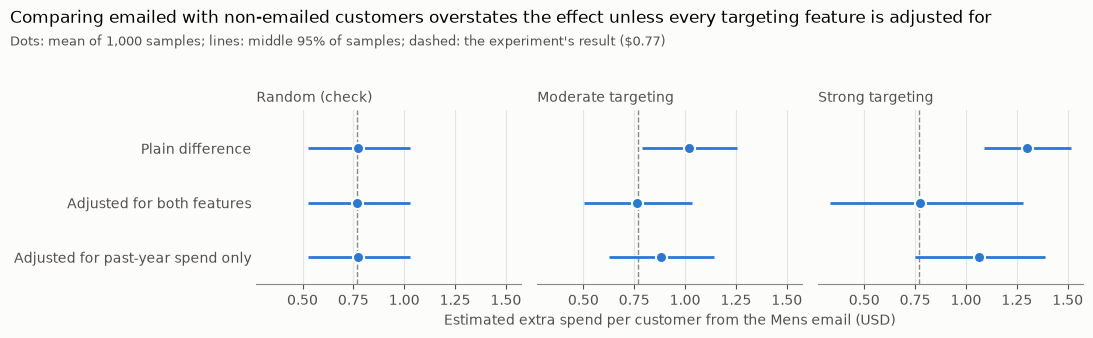

In [6]:
BLUE, GRAY, INK = "#2a78d6", "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "text.parse_math": False,
})

fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(11, 3.4), sharex=True, sharey=True)
positions = np.arange(len(ESTIMATORS))
for ax, scenario in zip(axes, SCENARIOS):
    part = results.loc[scenario]
    ax.axvline(benchmark, color=GRAY, linewidth=1, linestyle="--")
    ax.hlines(positions, part["2.5%"], part["97.5%"], color=BLUE, linewidth=2)
    ax.plot(part["mean estimate"], positions, "o", color=BLUE, markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    ax.set_title(scenario, loc="left", fontsize=10, color=INK)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(positions, labels=list(ESTIMATORS))
axes[0].set_ylim(len(ESTIMATORS) - 0.5, -0.7)
axes[1].set_xlabel("Estimated extra spend per customer from the Mens email (USD)")
fig.suptitle("Comparing emailed with non-emailed customers overstates the effect unless every targeting feature is adjusted for", x=0.01, ha="left", fontsize=12)
fig.text(0.01, 0.875, f"Dots: mean of {REPS:,} samples; lines: middle 95% of samples; dashed: the experiment's result (${benchmark:.2f})",
         ha="left", fontsize=9, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.88))
fig.savefig("../reports/figures/bias_demonstration.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** **the plain difference moves further from the experiment's result as targeting gets stronger, and under strong targeting the middle 95% of its samples (\$1.09 to \$1.52) no longer includes \$0.77.** Adjusting for both features stays centered on \$0.77 but spreads out, because few non-emailed customers with a score of 2 remain (about 430 per sample). Adjusting for past-year spend only stays off center.

**Summary of stage 05:** without random assignment, the plain comparison credits the email with spending that targeted customers would have done anyway. Adjustment removes this only when every feature used for targeting is recorded, which an analyst cannot check. Random assignment does not depend on it.